# 01. Load M5 and Build a Weekly, Single-Store Dataset

**Project 1: Forecast Accuracy Benchmark + Forecast Value Added (FVA)**

**Goal of this notebook:** turn the raw Kaggle M5 files into one clean table with one row per **SKU per week** for a single Walmart store. Every later notebook (forecasting, scoring, FVA) starts from this table.

**Output:** `data/processed/weekly_sku_<STORE_ID>.parquet`

**Steps**
1. Load only one store's rows from the large sales file
2. Reshape from wide (one column per day) to long (one row per SKU per day)
3. Attach real dates and Walmart's fiscal week from the calendar
4. Aggregate daily sales to weekly
5. Attach weekly prices and remove pre-launch weeks
6. Run sanity checks and save

## Setup
`STORE_ID` is the one setting you might change. Everything else follows from it.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STORE_ID = "CA_1"  # One Walmart store. Others: CA_2..CA_4, TX_1..TX_3, WI_1..WI_3

# Relative paths so the notebook runs on any computer.
# Works whether Jupyter starts in notebooks/ or in the project folder.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

for f in ["sales_train_evaluation.csv", "calendar.csv", "sell_prices.csv"]:
    print(f"{f:30s} found: {(RAW_DIR / f).exists()}")

sales_train_evaluation.csv     found: True
calendar.csv                   found: True
sell_prices.csv                found: True


## Step 1. Load one store from the sales file

`sales_train_evaluation.csv` is **wide**: one row per item per store (30,490 rows) and one column per day (`d_1` to `d_1941`). Loading it all at once can use several GB of memory.

Instead we read it in **chunks** of 5,000 rows, keep only our store's rows from each chunk, and throw the rest away. We also store daily sales as `int16` (whole numbers up to 32,767) instead of the default `int64`, which uses a quarter of the memory.

**Columns you need to know**
- `item_id`: the SKU, e.g. `FOODS_3_090`
- `dept_id`: department, e.g. `FOODS_3`
- `cat_id`: category: `FOODS`, `HOBBIES`, or `HOUSEHOLD`
- `store_id`, `state_id`: location
- `d_1` ... `d_1941`: units sold on each day

In [12]:
ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

header = pd.read_csv(RAW_DIR / "sales_train_evaluation.csv", nrows=0).columns
day_cols = [c for c in header if c.startswith("d_")]
dtypes = {c: "int16" for c in day_cols}

pieces = []
for chunk in pd.read_csv(RAW_DIR / "sales_train_evaluation.csv", dtype=dtypes, chunksize=5000):
    pieces.append(chunk[chunk["store_id"] == STORE_ID])
sales_wide = pd.concat(pieces, ignore_index=True)

print(f"Rows (SKUs) in {STORE_ID}: {len(sales_wide):,}")
print(f"Day columns: {len(day_cols):,}  ({day_cols[0]} to {day_cols[-1]})")
sales_wide.iloc[:3, :10]

Rows (SKUs) in CA_1: 3,049
Day columns: 1,941  (d_1 to d_1941)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


## Step 2. Reshape wide to long

Forecasting tools expect **long** format: one row per SKU per day, with columns `item_id`, `d`, `units`.

`melt` does this. If the store has *N* SKUs and there are *D* days, the long table has *N* x *D* rows.

In [13]:
sales_long = sales_wide.melt(
    id_vars=ID_COLS, value_vars=day_cols, var_name="d", value_name="units"
)
del sales_wide  # free memory

expected_rows = sales_long["item_id"].nunique() * len(day_cols)
print(f"Long rows: {len(sales_long):,}  (expected N x D = {expected_rows:,})")
sales_long.head()

Long rows: 5,918,109  (expected N x D = 5,918,109)


,id,item_id,dept_id,cat_id,store_id,state_id,d,units
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


## Step 3. Attach dates and Walmart weeks from the calendar

The sales file only has day codes like `d_1`. `calendar.csv` maps each code to:
- `date`: the real calendar date
- `wm_yr_wk`: **Walmart's fiscal week ID**. Walmart weeks run **Saturday to Friday**, not Monday to Sunday.
- `event_name_1`: holidays and events (Super Bowl, Easter, Thanksgiving...)
- `snap_CA`, `snap_TX`, `snap_WI`: 1 on days when SNAP (food stamp) benefits are paid out in that state

**Why use `wm_yr_wk` instead of making our own weeks?** Prices in `sell_prices.csv` are recorded per `wm_yr_wk`. Using the same week definition lets us join prices exactly, with no guessing.

In [14]:
calendar = pd.read_csv(RAW_DIR / "calendar.csv", parse_dates=["date"])
state = STORE_ID.split("_")[0]  # "CA" from "CA_1"

cal = calendar[["d", "date", "wm_yr_wk", "weekday", "event_name_1", f"snap_{state}"]].rename(
    columns={f"snap_{state}": "snap"}
)
sales_long = sales_long.merge(cal, on="d", how="left")

print("Missing dates after merge:", sales_long["date"].isna().sum())
print("Date range:", sales_long["date"].min().date(), "to", sales_long["date"].max().date())
print("First day is a:", sales_long["date"].min().day_name())

Missing dates after merge: 0
Date range: 2011-01-29 to 2016-05-22
First day is a: Saturday


## Step 4. Aggregate daily sales to weekly

**Why weekly?**
- Replenishment and S&OP plans are usually made in weekly buckets, so a weekly forecast is what a planner would actually use.
- Daily SKU sales are full of zeros (**intermittent demand**). Summing to weeks smooths the noise and makes accuracy metrics like MAPE more meaningful.

**For each SKU and week we compute**
- `units` = sum of the 7 daily sales
- `week_start` = first date of the week (a Saturday)
- `n_days` = number of days in the week (should be 7)
- `event_days` = days with a holiday or event
- `snap_days` = SNAP payout days

**Partial weeks:** the data ends mid-week, so the last week has fewer than 7 days. Comparing a 2-day week to 7-day weeks would look like a sales collapse, so we **drop any week with `n_days` < 7**.

In [15]:
weekly = (
    sales_long.groupby(["item_id", "dept_id", "cat_id", "store_id", "wm_yr_wk"], observed=True)
    .agg(
        week_start=("date", "min"),
        units=("units", "sum"),
        n_days=("date", "count"),
        event_days=("event_name_1", "count"),  # count() skips blanks, so this counts event days
        snap_days=("snap", "sum"),
    )
    .reset_index()
)

total_units_daily = int(sales_long["units"].sum())
del sales_long

partial = weekly.loc[weekly["n_days"] < 7, ["wm_yr_wk", "week_start", "n_days"]].drop_duplicates()
print("Partial weeks found:")
print(partial.to_string(index=False))

units_in_partial = int(weekly.loc[weekly["n_days"] < 7, "units"].sum())
weekly = weekly[weekly["n_days"] == 7].drop(columns="n_days")

# Sanity check 1: no units lost except those in the dropped partial weeks
assert int(weekly["units"].sum()) + units_in_partial == total_units_daily
print("\nCheck passed: daily total = weekly total + units in partial weeks")
print(f"Full weeks kept: {weekly['wm_yr_wk'].nunique()}")

Partial weeks found:
 wm_yr_wk week_start  n_days
    11617 2016-05-21       2

Check passed: daily total = weekly total + units in partial weeks
Full weeks kept: 277


## Step 5. Attach weekly prices and remove pre-launch weeks

`sell_prices.csv` has one row per store, item, and week **when the item was on sale**. If there is no price for a week, the item was **not on the shelf yet**.

**Why this matters (a common interview point):** M5 fills those pre-launch weeks with 0 sales. Those zeros are not "zero demand." The product did not exist yet. Leaving them in would:
- make new products look like they had a long history of no sales
- drag down forecasts and distort accuracy metrics

So we keep only weeks **on or after the first week the item had a price**.

`revenue` = `units` x `sell_price`. We will use it later to weight accuracy by dollar impact.

In [16]:
prices = pd.read_csv(RAW_DIR / "sell_prices.csv")
prices = prices[prices["store_id"] == STORE_ID].drop(columns="store_id")

weekly = weekly.merge(prices, on=["item_id", "wm_yr_wk"], how="left")

first_price_wk = prices.groupby("item_id")["wm_yr_wk"].min().rename("launch_wk")
weekly = weekly.merge(first_price_wk, on="item_id", how="left")

before = len(weekly)
prelaunch_units = int(weekly.loc[weekly["wm_yr_wk"] < weekly["launch_wk"], "units"].sum())
weekly = weekly[weekly["wm_yr_wk"] >= weekly["launch_wk"]].drop(columns="launch_wk")

print(f"Pre-launch rows removed: {before - len(weekly):,}")
print(f"Units sold in pre-launch weeks (should be 0): {prelaunch_units}")
print(f"Rows still missing a price after launch: {weekly['sell_price'].isna().sum():,}")

weekly["revenue"] = weekly["units"] * weekly["sell_price"]

Pre-launch rows removed: 161,406
Units sold in pre-launch weeks (should be 0): 0
Rows still missing a price after launch: 0


## Step 6. Sanity checks and a first look

Before modeling, confirm the table is what we think it is:
- one row per SKU per week (no duplicates)
- no negative sales
- how many SKUs and weeks we have
- how **intermittent** each category is: the share of SKU-weeks with zero sales. High zero shares break MAPE (you cannot divide by zero), which is why WAPE will be our main metric later.

In [17]:
weekly = weekly.sort_values(["item_id", "week_start"]).reset_index(drop=True)

assert not weekly.duplicated(["item_id", "wm_yr_wk"]).any(), "Duplicate SKU-weeks found"
assert (weekly["units"] >= 0).all(), "Negative sales found"

print(f"Store: {STORE_ID}")
print(f"SKUs: {weekly['item_id'].nunique():,}")
print(f"Weeks: {weekly['wm_yr_wk'].nunique()}  ({weekly['week_start'].min().date()} to {weekly['week_start'].max().date()})")
print(f"Rows (SKU-weeks): {len(weekly):,}")

summary = weekly.groupby("cat_id").agg(
    skus=("item_id", "nunique"),
    total_units=("units", "sum"),
    total_revenue=("revenue", "sum"),
    zero_week_share=("units", lambda s: (s == 0).mean()),
)
summary["unit_share"] = summary["total_units"] / summary["total_units"].sum()
summary["revenue_share"] = summary["total_revenue"] / summary["total_revenue"].sum()
summary.style.format({
    "total_units": "{:,.0f}", "total_revenue": "${:,.0f}",
    "zero_week_share": "{:.1%}", "unit_share": "{:.1%}", "revenue_share": "{:.1%}",
})

Store: CA_1
SKUs: 3,049
Weeks: 277  (2011-01-29 to 2016-05-14)
Rows (SKU-weeks): 683,167


,skus,total_units,total_revenue,zero_week_share,unit_share,revenue_share
cat_id,,,,,,
FOODS,1437,"5,463,551","$13,605,924",18.3%,69.9%,59.4%
HOBBIES,565,"890,718","$3,219,340",25.1%,11.4%,14.0%
HOUSEHOLD,1047,"1,465,926","$6,089,272",21.7%,18.7%,26.6%


**Weekly units by category.** Look for trend, yearly seasonality, and the Christmas dip (Walmart stores closed on Christmas Day).

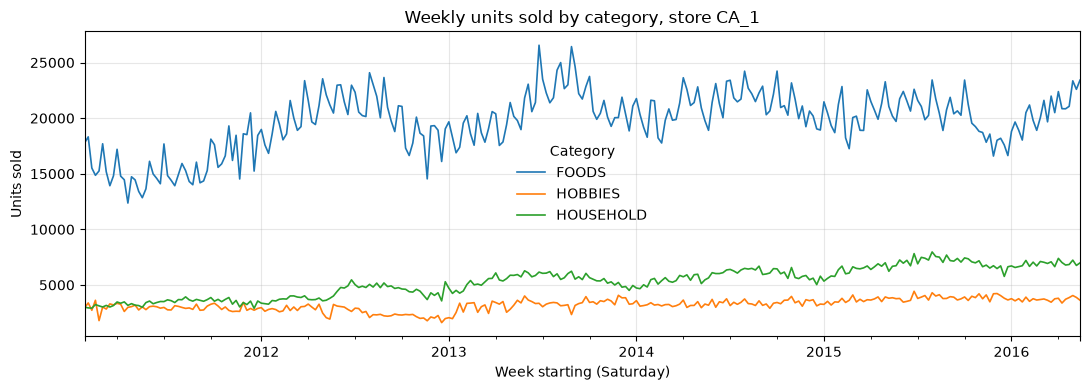

In [18]:
by_cat = weekly.pivot_table(index="week_start", columns="cat_id", values="units", aggfunc="sum")

fig, ax = plt.subplots(figsize=(11, 4))
by_cat.plot(ax=ax, linewidth=1.2)
ax.set_title(f"Weekly units sold by category, store {STORE_ID}")
ax.set_xlabel("Week starting (Saturday)")
ax.set_ylabel("Units sold")
ax.grid(alpha=0.3)
ax.legend(title="Category", frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / f"weekly_units_by_category_{STORE_ID}.png", dpi=150)
plt.show()

## Save the processed table

Parquet is a compressed format that keeps column types (dates stay dates). It is much smaller than CSV and loads faster.

In [19]:
out_path = PROCESSED_DIR / f"weekly_sku_{STORE_ID}.parquet"
weekly.to_parquet(out_path, index=False)
print(f"Saved {len(weekly):,} rows to {out_path.relative_to(PROJECT_DIR)}")
print(f"File size: {out_path.stat().st_size / 1e6:.1f} MB")
weekly.head()

Saved 683,167 rows to data/processed/weekly_sku_CA_1.parquet
File size: 2.3 MB


,item_id,dept_id,cat_id,store_id,wm_yr_wk,week_start,units,event_days,snap_days,sell_price,revenue
0,FOODS_1_001,FOODS_1,FOODS,CA_1,11101,2011-01-29,10,0,4,2.0,20.0
1,FOODS_1_001,FOODS_1,FOODS,CA_1,11102,2011-02-05,6,1,6,2.0,12.0
2,FOODS_1_001,FOODS_1,FOODS,CA_1,11103,2011-02-12,10,1,0,2.0,20.0
3,FOODS_1_001,FOODS_1,FOODS,CA_1,11104,2011-02-19,13,1,0,2.0,26.0
4,FOODS_1_001,FOODS_1,FOODS,CA_1,11105,2011-02-26,15,0,4,2.0,30.0


## Notes for the README (Data and Limitations)
- **Sales, not demand.** M5 records units sold. When an item was out of stock, true demand was higher than recorded sales. We cannot see stockouts directly, so forecasts here predict sales.
- **Pre-launch weeks removed** using the first week each item had a price.
- **Partial final week removed** so every week has 7 days.
- **Weeks follow Walmart's fiscal calendar** (Saturday to Friday) to match the price data.